## Objective

The objective of this analysis is to study the distribution of a specific type of cargo arriving at a selected station using historical simulation data. This analysis aims to detect patterns, variability, and potential anomalies by visualising the data through a histogram.

## Theoretical Concepts

This analysis focuses on the following variable:

- **[Selected Cargo Type]**: Represents the amount of a specific cargo (e.g., *Iron*, *Coffee*, *Passengers*) arriving at a station. This is a **quantitative continuous variable**, typically measured in **tons** (for materials like coal, steel, vegetables, etc.) or as a **number** (for passengers).

### Histogram Construction

A histogram is a graphical representation of data in which:

- **Classes** are displayed on the horizontal axis;
- **Frequencies** are displayed on the vertical axis;
- **Bars** are adjacent and have an area proportional to the frequency of the corresponding class.

In building a histogram for a continuous quantitative variable, each class is an interval of the form \[a, b[ or ]a, b], representing a range of possible values. The following elements must be defined:

- **Class amplitude** (width of each class):

  $$
  \text{Amplitude} = b - a
  $$

- **Class midpoint** (also called mark or characteristic value):

  $$
  \text{Midpoint} = \frac{a + b}{2}
  $$

- **Number of classes (c)** can be estimated using **Sturges' Rule**:

  $$
  c = \lfloor 1 + 3.3 \log_{10}(n) \rfloor
  $$

  where \( n \) is the number of observations and \( \lfloor x \rfloor \) denotes the integer part of \( x \).

### Interpretation

Histograms are useful for:

- Understanding the shape and spread of the data;
- Identifying central tendencies, skewness, and variability;
- Detecting outliers or irregular patterns.


Available Stations:
1. Stuttgart
2. Frankfurt
3. Hannover
4. Hamburg
5. Berlin

Available Cargo Types:
1. Iron
2. Coal
3. Prata
4. Vegetables
5. Cereals
6. Wool
7. Coffee
8. Cattle
9. Passengers
10. Mail


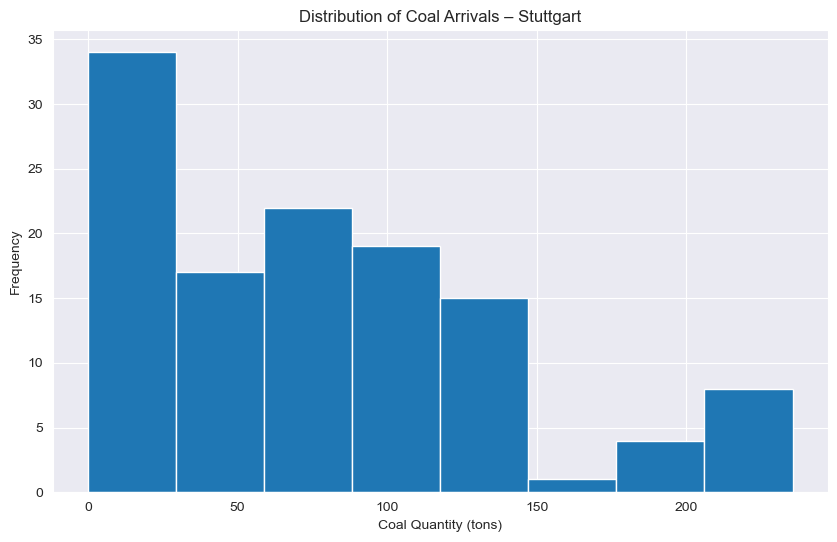

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

cargo_columns = [col for col in df.columns if col not in ['Station', 'Year', 'Month', 'Arrivals', 'Revenues', 'Expenses']]

for col in cargo_columns:
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)

stations = df['Station'].unique()

print("Available Stations:")
for i, station in enumerate(stations, 1):
    print(f"{i}. {station}")

station_choice = int(input("Choose a station by number: ")) - 1
station_name = stations[station_choice]

print("\nAvailable Cargo Types:")
for i, cargo in enumerate(cargo_columns, 1):
    print(f"{i}. {cargo}")

cargo_choice = int(input("Choose a cargo type by number: ")) - 1
cargo_type = cargo_columns[cargo_choice]

filtered_data = df[df['Station'] == station_name][['Year', 'Month', 'Arrivals', cargo_type]]

plt.figure(figsize=(10, 6))

if cargo_type == "Passengers":
    plt.xlabel(f"Number of {cargo_type}")
else:
    plt.xlabel(f"{cargo_type} Quantity (tons)")

plt.hist(filtered_data[cargo_type], bins='auto')
plt.title(f'Distribution of {cargo_type} Arrivals – {station_name}')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

## Analysis and Interpretation of Results

The histograms generated for each station and cargo type provide a visual representation of the distribution of cargo arrivals across different months and years. These histograms illustrate the frequency of each cargo type’s arrival, but they do not allow direct comparison between different cargo types or stations without further analysis.

In the context of the **Projeto Integrador (PI)** this graphical representation allows the player to better understand how cargo traffic varies by station and cargo type. The histograms help identify which cargo types are being transported more frequently in specific stations.

With this information, the player can optimise transport routes and station management, potentially prioritising cargo types that appear more often in specific stations to enhance operational efficiency within the simulation.
